In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load dataset
df = pd.read_csv(
    "../datasets/raw/graduate_admissions/Admission_Predict.csv"
)

# Clean column names
df.columns = df.columns.str.strip()

# Remove ID column
df = df.drop(columns=["Serial No."])

# Separate features and target
X = df.drop(columns=["Chance of Admit"])
y = df["Chance of Admit"]

# Same 80:20 split used in previous models
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (320, 7)
Testing shape: (80, 7)


In [3]:
alpha_values = np.logspace(-4, 2, 20)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Alpha values:")
print(alpha_values)

Alpha values:
[1.00000000e-04 2.06913808e-04 4.28133240e-04 8.85866790e-04
 1.83298071e-03 3.79269019e-03 7.84759970e-03 1.62377674e-02
 3.35981829e-02 6.95192796e-02 1.43844989e-01 2.97635144e-01
 6.15848211e-01 1.27427499e+00 2.63665090e+00 5.45559478e+00
 1.12883789e+01 2.33572147e+01 4.83293024e+01 1.00000000e+02]


In [4]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best Ridge CV MSE:", -ridge_grid.best_score_)

Best Ridge alpha: 23.357214690901213
Best Ridge CV MSE: 0.004225298692794704


In [5]:
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=100000))
])

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])
print("Best Lasso CV MSE:", -lasso_grid.best_score_)

Best Lasso alpha: 0.0008858667904100823
Best Lasso CV MSE: 0.004256185571217418


In [6]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

models = {
    "Ridge": best_ridge,
    "Lasso": best_lasso
}

results = []

for name, model in models.items():

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Training metrics
    train_mse = mean_squared_error(y_train, train_pred)
    train_rmse = np.sqrt(train_mse)
    train_r2 = r2_score(y_train, train_pred)

    # Testing metrics
    test_mse = mean_squared_error(y_test, test_pred)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Best Alpha": model.named_steps["model"].alpha,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R2": train_r2,
        "Test R2": test_r2
    })

regularization_results = pd.DataFrame(results)

display(regularization_results.round(5))

,Model,Best Alpha,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,Ridge,23.35721,0.00391,0.00480,0.06254,0.06930,0.79306,0.81401
1,Lasso,0.00089,0.00387,0.00466,0.06222,0.06829,0.79513,0.81943


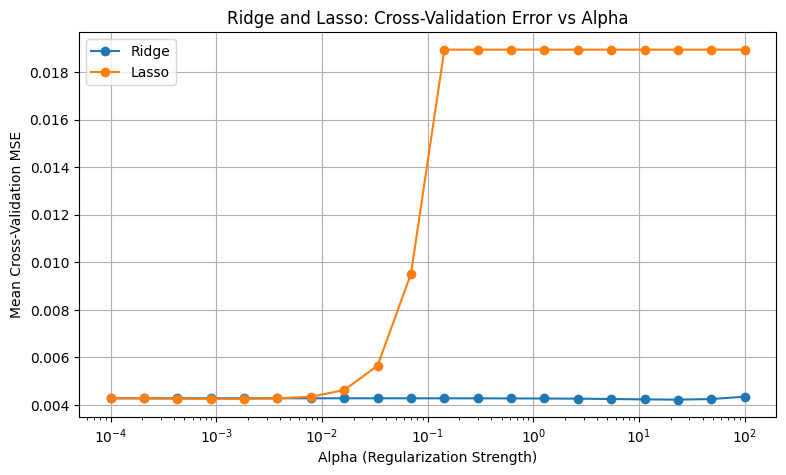

In [7]:
ridge_cv_mse = -ridge_grid.cv_results_["mean_test_score"]
lasso_cv_mse = -lasso_grid.cv_results_["mean_test_score"]

plt.figure(figsize=(9, 5))

plt.semilogx(alpha_values, ridge_cv_mse, marker="o", label="Ridge")
plt.semilogx(alpha_values, lasso_cv_mse, marker="o", label="Lasso")

plt.xlabel("Alpha (Regularization Strength)")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Ridge and Lasso: Cross-Validation Error vs Alpha")

plt.legend()
plt.grid(True)
plt.show()

In [8]:
coefficient_comparison = pd.DataFrame({
    "Feature": X.columns,
    "Ridge Coefficient": best_ridge.named_steps["model"].coef_,
    "Lasso Coefficient": best_lasso.named_steps["model"].coef_
})

display(coefficient_comparison.round(5))

,Feature,Ridge Coefficient,Lasso Coefficient
0,GRE Score,0.02418,0.02094
1,TOEFL Score,0.01916,0.01608
2,University Rating,0.01074,0.00813
3,SOP,0.00321,0.00000
4,LOR,0.01483,0.01358
5,CGPA,0.05387,0.06744
6,Research,0.01106,0.01059
